# 01 · Tarefa da IA e base de conhecimento

**Boca de Lobo · Generative AI for Engineering · GS 2026.2**

Este notebook cobre os itens **01** (tarefa da IA) e **02** (base de conhecimento, em trechos com fonte) da pontuação.

## A tarefa

O morador de um bairro que alaga pergunta, em linguagem do dia a dia, o que fazer antes, durante e depois do alagamento, como pedir ajuda e quais direitos tem. A IA responde **só com o que está em fontes oficiais**, **cita a fonte** e **recusa** quando a informação não consta.

| | |
|---|---|
| Entrada | pergunta em texto livre (até 500 caracteres) |
| Saída | JSON com `recusa`, `resposta`, `fontes` (trechos citados, com órgão e URL), `evidencia`, `motivo`, `confianca` |
| Modelo | LLM local (`gemma3:4b`, 4 bilhões de parâmetros, quantizado, rodando em CPU pelo Ollama) |
| Por que local | a pergunta do morador não sai da infraestrutura do produto (LGPD) e não há custo por chamada |
| O que a IA não faz | não decide nada sobre o morador: orienta e aponta o canal oficial. Quem atende é a Defesa Civil, a Prefeitura ou o serviço de saúde |

In [1]:
import os, sys, json
from pathlib import Path
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
os.environ["MAPA_URL"] = ""   # notebooks usam a cópia local do mapa, para as saídas serem reproduzíveis
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 160); pd.set_option("display.width", 220)
from boca_de_lobo_ia import config
print("modelo LLM:", config.MODELO_LLM, "| embeddings:", config.MODELO_EMBEDDING, "| Ollama:", config.OLLAMA_URL)

modelo LLM: gemma3:4b | embeddings: bge-m3 | Ollama: http://127.0.0.1:11434


## Fontes

O catálogo fica em `base/fontes.json`. Cada fonte tem um `tipo_texto`:

* **literal**: o texto foi extraído automaticamente do original. Só entra como literal o que pode ser reproduzido: atos oficiais (leis e decretos não têm proteção autoral, Lei 9.610/98, art. 8º, IV) e páginas do portal gov.br, que declaram licença CC BY-ND 3.0.
* **ficha**: a página não declara licença de reprodução (Prefeitura de São Paulo, CGE, Governo do Estado) ou é um PDF diagramado que não extrai bem. Nesses casos a equipe escreveu uma **ficha-resumo** com os fatos e o link para o original.

In [2]:
from collections import Counter
from boca_de_lobo_ia import coleta, trechos

fontes = coleta.carregar_fontes()
ts = trechos.carregar()
por_fonte = Counter(t.fonte_id for t in ts)
palavras = Counter()
for t in ts:
    palavras[t.fonte_id] += t.palavras

tabela = pd.DataFrame([{
    "id": f["id"], "fonte": f["titulo"], "órgão": f["orgao"], "formato": f["formato"],
    "texto": f["tipo_texto"], "licença": f["licenca"], "trechos": por_fonte[f["id"]], "palavras": palavras[f["id"]],
} for f in fontes])
print(len(fontes), "fontes |", len(ts), "trechos |", int(tabela["palavras"].sum()), "palavras")
tabela

22 fontes | 146 trechos | 11063 palavras


,id,fonte,órgão,formato,texto,licença,trechos,palavras
0,midr_chuvas,Chuvas intensas: saiba como agir,Secretaria Nacional de Proteção e Defesa Civil (MIDR),PDF,literal,CC BY-ND 3.0 (padrão do portal gov.br),3,222
1,midr_alerta,Defesa Civil Alerta,Ministério da Integração e do Desenvolvimento Regional (MIDR),HTML,literal,CC BY-ND 3.0 (rodapé da página),27,1228
2,mma_protocolo,"Protocolo de emergência climática: inundações, enchentes e alagamentos",Ministério do Meio Ambiente e Mudança do Clima (MMA),PDF,ficha,"Reprodução sem fins lucrativos permitida, citada a fonte (ficha catalográfica); usada como ficha-resumo porque o PDF é diagramado",8,593
3,ms_enchentes,Enchentes: cuidados com a saúde,Ministério da Saúde,HTML,literal,CC BY-ND 3.0 (rodapé da página),5,443
4,ms_agua,Enchentes: cuidados com a água,Ministério da Saúde,HTML,literal,CC BY-ND 3.0 (rodapé da página),3,290
5,ms_alimentos,Enchentes: cuidados com os alimentos,Ministério da Saúde,HTML,literal,CC BY-ND 3.0 (rodapé da página),2,158
6,ms_leptospirose,Enchentes: cuidados com a leptospirose,Ministério da Saúde,HTML,literal,CC BY-ND 3.0 (rodapé da página),1,137
7,ms_tetano,Enchentes: cuidados com o risco de tétano,Ministério da Saúde,HTML,literal,CC BY-ND 3.0 (rodapé da página),2,232
8,ms_peconhentos,Enchentes: cuidados com animais peçonhentos,Ministério da Saúde,HTML,literal,CC BY-ND 3.0 (rodapé da página),2,217
9,lei_12608,Lei nº 12.608/2012: Política Nacional de Proteção e Defesa Civil,Presidência da República (Planalto),HTML,literal,"Ato oficial, sem proteção autoral (Lei 9.610/98, art. 8º, IV)",13,1595


In [3]:
tabela.groupby("texto").agg(fontes=("id", "count"), trechos=("trechos", "sum"), palavras=("palavras", "sum"))

,fontes,trechos,palavras
texto,,,
ficha,9,40,2710
literal,13,106,8353


## Coleta

`coleta.coletar()` baixa cada fonte (com cache em `base/bruto/`, fora do Git), extrai o texto das fontes literais e confere se as páginas das fichas continuam no ar. O `sha256` identifica a versão baixada.

Para baixar tudo de novo: `python scripts/construir_base.py --atualizar`.

In [4]:
resumo = pd.DataFrame(coleta.coletar())
resumo

,id,tipo_texto,situacao,blocos,sha256
0,midr_chuvas,literal,ok,17.0,d0518dca6f41a7fe
1,midr_alerta,literal,ok,77.0,7b944d7304dba22c
2,mma_protocolo,ficha,ok,NaN,26f22a44e2f57ffa
3,ms_enchentes,literal,ok,21.0,523f78a4913ba6e5
4,ms_agua,literal,ok,15.0,e9fbce0a73257215
5,ms_alimentos,literal,ok,7.0,5f79201a22baabd3
6,ms_leptospirose,literal,ok,7.0,4c13792cd9b3b114
7,ms_tetano,literal,ok,11.0,0b9a572e125465e7
8,ms_peconhentos,literal,ok,13.0,44cfeb5fb958bb79
9,lei_12608,literal,ok,51.0,01fdf061b289cd74


### Um cuidado que evitou resposta errada: texto revogado

As páginas do Planalto mantêm as redações antigas **riscadas**. No Decreto 5.113/2004 o limite do saque do FGTS aparece quatro vezes (R$ 2.600, R$ 4.650, R$ 5.400 e o vigente, R$ 6.220). A extração remove o que está riscado (`<strike>` e `text-decoration: line-through`). Sem isso, a base teria quatro valores para a mesma pergunta.

In [5]:
bruto = (config.DIR_BRUTO / "decreto_5113.html").read_bytes().decode("cp1252")
tratado = (config.DIR_DOCUMENTOS / "decreto_5113.md").read_text(encoding="utf-8")
for valor in ["2.600,00", "4.650,00", "5.400,00", "6.220,00"]:
    print(f"R$ {valor}: no HTML original = {valor in bruto} | no documento tratado = {valor in tratado}")

R$ 2.600,00: no HTML original = True | no documento tratado = False
R$ 4.650,00: no HTML original = True | no documento tratado = False
R$ 5.400,00: no HTML original = True | no documento tratado = False
R$ 6.220,00: no HTML original = True | no documento tratado = True


### Exemplo de documento literal (lei) e de ficha-resumo

In [6]:
print((config.DIR_DOCUMENTOS / "decreto_5113.md").read_text(encoding="utf-8")[:1500])

---
id: decreto_5113
titulo: Decreto nº 5.113/2004: saque do FGTS por desastre natural
orgao: Presidência da República (Planalto)
url: https://www.planalto.gov.br/ccivil_03/_ato2004-2006/2004/decreto/d5113.htm
formato: HTML
licenca: Ato oficial, sem proteção autoral (Lei 9.610/98, art. 8º, IV)
tipo_texto: literal
acessado_em: 2026-11-10
---

# Decreto nº 5.113/2004: saque do FGTS por desastre natural

## Art. 1º

Art. 1º O titular de conta vinculada do Fundo de Garantia do Tempo de Serviço - FGTS que resida em área do Distrito Federal ou de Município, em situação de emergência ou estado de calamidade pública objeto de decreto do respectivo Governo, poderá movimentar a referida conta por motivo de necessidade pessoal, cuja urgência e gravidade decorram de desastre natural.

§ 1º Para os fins da movimentação de que trata este artigo, o decreto municipal ou do Distrito Federal que declare a situação de emergência ou o estado de calamidade pública deverá ser publicado no prazo máximo de tr

In [7]:
print((config.DIR_DOCUMENTOS / "sehab_cartao.md").read_text(encoding="utf-8"))

---
id: sehab_cartao
titulo: Cartão Emergencial para famílias afetadas por desastres
orgao: Secretaria Municipal de Habitação de São Paulo (SEHAB)
url: https://prefeitura.sp.gov.br/web/habitacao/w/cartão-emergencial-garante-apoio-imediato-a-famílias-afetadas-por-desastres-naturais
formato: HTML
licenca: Não declarada na página; usada como ficha-resumo com link para o original
tipo_texto: ficha
acessado_em: 2026-11-10
---
# Cartão Emergencial para famílias afetadas por desastres

> Ficha-resumo escrita pela equipe a partir da página oficial indicada em `url`. Não é transcrição: para o texto original, consulte o link.

## Cartão Emergencial: o que é e qual o valor

O Cartão Emergencial é um auxílio da Prefeitura de São Paulo, pago pela Secretaria Municipal de Habitação (SEHAB), para famílias que tiveram a moradia comprometida por risco iminente, desastre natural ou calamidade pública, como enchente, desabamento ou incêndio. O auxílio é um pagamento único de R$ 1.000, para cobrir despesas

## Trechos

Regras de divisão (`src/boca_de_lobo_ia/trechos.py`):

* um trecho nunca mistura seções (em lei, a seção é o artigo; em FAQ, a pergunta);
* alvo de 110 palavras, máximo de 170, cortando só em fim de parágrafo ou item de lista;
* todo trecho carrega título, seção, órgão, URL e licença: é o que permite citar.

O tamanho foi escolhido pelo contexto da LLM em CPU: 3 trechos de até 170 palavras cabem com folga em 4.096 tokens e deixam a resposta rápida.

count    146.0
mean      75.8
std       40.1
min       12.0
25%       43.0
50%       68.5
75%      110.8
max      165.0


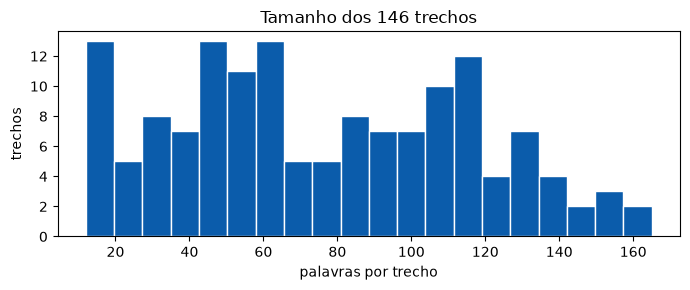

In [8]:
df = pd.DataFrame([t.__dict__ for t in ts])
print(df["palavras"].describe().round(1).to_string())
ax = df["palavras"].plot.hist(bins=20, figsize=(7, 3), color="#0b5cab", edgecolor="white")
ax.set_xlabel("palavras por trecho"); ax.set_ylabel("trechos"); ax.set_title("Tamanho dos 146 trechos")
plt.tight_layout(); plt.show()

In [9]:
df[df["id"].isin(["decreto_5113#07", "ms_agua#02", "dcsp_chuvas#04", "midr_alerta#09"])][["id", "orgao", "secao", "tipo_texto", "palavras", "texto", "url"]]

,id,orgao,secao,tipo_texto,palavras,texto,url
10,dcsp_chuvas#04,Defesa Civil da Prefeitura de São Paulo,Durante o alagamento: quem está no carro,ficha,66,- Diminuir a velocidade e manter distância do veículo da frente.\n- Procurar parar o carro em local alto e livre de enchente.\n- Ouvir o rádio para saber o ...,https://prefeitura.sp.gov.br/web/defesa_civil/w/cuidados_importantes/179951
19,decreto_5113#07,Presidência da República (Planalto),Art. 4º,literal,96,"Art. 4º O valor do saque será equivalente ao saldo existente na conta vinculada, na data da solicitação, limitado à quantia correspondente a R$ 6.220,00 (se...",https://www.planalto.gov.br/ccivil_03/_ato2004-2006/2004/decreto/d5113.htm
86,midr_alerta#09,Ministério da Integração e do Desenvolvimento Regional (MIDR),7. Preciso fazer algum cadastro prévio para receber as notificações do Defesa Civil Alerta?,literal,18,Não há necessidade de cadastro prévio ou quaisquer providências adicionais para recebimento das notificações via Defesa Civil Alerta.,https://www.gov.br/mdr/pt-br/assuntos/protecao-e-defesa-civil/defesa-civil-alerta
117,ms_agua#02,Ministério da Saúde,Tratamento de água,literal,89,Antes de manipular a água lavar sempre as mãos e os braços para não a contaminar. Separe um recipiente higienizado com tampa e com boca preferencialmente es...,https://www.gov.br/saude/pt-br/assuntos/saude-de-a-a-z/e/enchentes/cuidados-com-a-agua


### Fontes que divergem entre si

A base guarda o que cada órgão diz, mesmo quando eles não concordam. Dois casos reais, que viram casos de teste:

* tempo de espera depois de pingar o hipoclorito na água: **30 minutos** (Ministério da Saúde) e **10 minutos** depois de ferver e pingar (Secretaria Municipal da Saúde);
* água sanitária na limpeza: **um copo por balde de 20 litros** para objetos (Defesa Civil municipal) e **400 mL por balde de 20 litros** para pisos e paredes (Secretaria Municipal da Saúde).

A regra 6 do prompt manda informar as duas orientações, dizendo de quem é cada uma.

In [10]:
for i in ["ms_agua#02", "sms_folder#02", "dcsp_chuvas#05", "sms_folder#03"]:
    t = next(t for t in ts if t.id == i)
    print(f"[{t.id}] {t.orgao}\n{t.texto[:420]}\n")

[ms_agua#02] Ministério da Saúde
Antes de manipular a água lavar sempre as mãos e os braços para não a contaminar. Separe um recipiente higienizado com tampa e com boca preferencialmente estreita, apenas para guardar a água tratada para beber.
Opção 1 - Filtra e Desinfetar
- Filtrar ou coar a água com filtro doméstico, coador de papel ou pano limpo;
- Após a filtração, adicionar 2 gotas de hipoclorito de sódio a 2,5% para cada 1 litro de água;
- Mis

[sms_folder#02] Secretaria Municipal da Saúde de São Paulo (Coordenadoria de Vigilância em Saúde)
- Beber sempre água potável e não usar água de fonte não confiável. Se necessário, ferver a água, pingar duas gotas de hipoclorito de sódio a 2,5% para cada litro e esperar 10 minutos antes de consumir.
- Não usar água de poço, a não ser para lavar quintal e calçada.
- Usar água potável para escovar os dentes e para preparar alimentos e bebidas, principalmente para crianças menores de um ano e idosos.
- Não consumir 

[dcsp_chuvas#05] Defesa C

## Resumo

* 22 fontes oficiais (federais, estaduais e municipais), 146 trechos, todos com órgão, URL e licença.
* 13 fontes entram com texto literal (5 atos oficiais e 8 páginas gov.br) e 9 como ficha-resumo.
* A tabela exigida no relatório (fonte, formato, licença e número de trechos) é a primeira tabela deste notebook.

Próximo: `02_busca_recall_limiar.ipynb`.